In [ ]:
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             ConfusionMatrixDisplay, classification_report)

FEATS = "features_r21d.npy"   # features.npy / features_ft.npy / features_r21d.npy

df = pd.read_csv("index.csv")
feats = np.load(FEATS)
print(FEATS, feats.shape)

X = feats.mean(axis=1) if feats.ndim == 3 else feats   # кадровые признаки усредняем по времени
y = df.label.values                                    # 0 = eat, 1 = drink
tv = (df.split != "test").values                       # train + val
X_tv, y_tv, g_tv = X[tv], y[tv], df.source[tv].values
X_te, y_te = X[~tv], y[~tv]
print(X_tv.shape, X_te.shape)

(192, 512) (80, 512)


In [2]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0)

candidates = {
    "Dummy (majority)": (DummyClassifier(strategy="most_frequent"), {}),
    "LogReg": (LogisticRegression(max_iter=5000, class_weight="balanced"),
               {"clf__C": [0.001, 0.01, 0.1, 1]}),
    "SVM linear": (SVC(kernel="linear", class_weight="balanced"),
                   {"clf__C": [0.001, 0.01, 0.1, 1]}),
    "SVM rbf": (SVC(kernel="rbf", class_weight="balanced"),
                {"clf__C": [0.1, 1, 10, 100], "clf__gamma": ["scale", 1e-3, 1e-4]}),
}

rows, models = [], {}
for name, (est, grid) in candidates.items():
    pipe = Pipeline([("scaler", StandardScaler()), ("clf", est)])   # масштабирование + классификатор
    gs = GridSearchCV(pipe, grid, cv=cv, scoring="balanced_accuracy")
    gs.fit(X_tv, y_tv, groups=g_tv)       # после подбора дообучается на всём train+val
    pred = gs.predict(X_te)
    models[name] = gs.best_estimator_
    rows.append({"model": name, "params": gs.best_params_,
                 "cv_bal_acc": gs.best_score_,
                 "test_acc": accuracy_score(y_te, pred),
                 "test_bal_acc": balanced_accuracy_score(y_te, pred),
                 "test_f1_macro": f1_score(y_te, pred, average="macro")})

res = pd.DataFrame(rows).round(3)
res.to_csv("results_svm.csv", index=False)
res

,model,params,cv_bal_acc,test_acc,test_bal_acc,test_f1_macro
0,Dummy (majority),{},0.500,0.575,0.500,0.365
1,LogReg,{'clf__C': 1},0.634,0.650,0.646,0.644
2,SVM linear,{'clf__C': 0.001},0.608,0.700,0.708,0.699
3,SVM rbf,"{'clf__C': 10, 'clf__gamma': 0.0001}",0.616,0.688,0.694,0.686


LogReg
              precision    recall  f1-score   support

         eat       0.58      0.62      0.60        34
       drink       0.70      0.67      0.69        46

    accuracy                           0.65        80
   macro avg       0.64      0.65      0.64        80
weighted avg       0.65      0.65      0.65        80



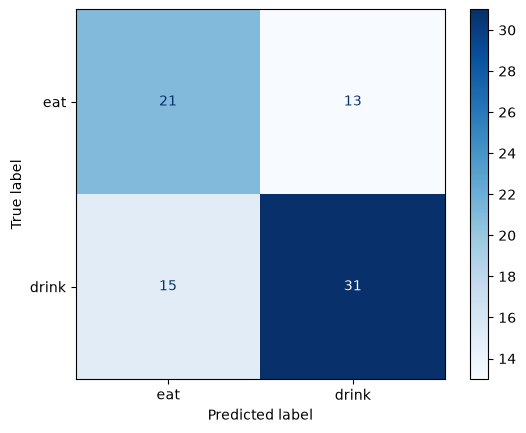

In [3]:
best = res.iloc[1:].sort_values("cv_bal_acc").iloc[-1].model   # выбор по CV, не по test
pred = models[best].predict(X_te)
print(best)
print(classification_report(y_te, pred, target_names=["eat", "drink"]))
ConfusionMatrixDisplay.from_predictions(y_te, pred, display_labels=["eat", "drink"], cmap="Blues");